# Adaptive RAG: results analysis
Compares rag_abstention with the adaptive systems on the same questions.

In [1]:
# Imports
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from reliable_rag.evaluation.metrics import exact_match, normalize_answer, token_f1

## Runs to analyse
Take note: Change folder names for different runs.

In [2]:
OUTPUTS = Path("..") / "outputs"

RUNS = {
    "rag_abstention": "run01-dev500-rag",
    "adaptive_retrieval": "run01-dev500-adaptive",
    "adaptive_retrieval_abstention": "run01-dev500-adaptive-abst",
}

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

## Load records
One row per question per system. Correctness uses the same EM/F1 as evaluate_results.py.

In [3]:
# Loader function

def load_run(system: str, run_id: str) -> list[dict]:
    """Turn one run's results.jsonl into one row per question."""
    rows = []
    with open(OUTPUTS / run_id / "results.jsonl", encoding="utf-8") as f:
        for line in f:
            record = json.loads(line)
            answer = record["final_answer"]["answer"] or ""
            gold = record["question"]["gold_answer"]
            answered = not record["final_answer"]["abstained"]

            rows.append({
                "system": system,
                "question_id": record["question"]["question_id"],
                "condition": record["condition"],
                "answered": answered,
                "abstention_reason": record["final_answer"]["abstention_reason"],
                "answer": answer,
                "gold": gold,
                # Correctness only counts when it answered, as in evaluate_results.py.
                "em": exact_match(answer, gold) if answered else None,
                "f1": token_f1(answer, gold) if answered else None,
                "rounds": len(record["rounds"]),
                "round0_status": record["rounds"][0]["sufficiency_decision"]["status"],
                "gold_init": record["gold_sufficient_initially"],
                "gold_final": record["gold_sufficient_finally"],
                "pred_init": record["model_predicted_sufficient_initially"],
                "pred_final": record["model_predicted_sufficient_finally"],
            })
    return rows

In [4]:
# Build table

df = pd.DataFrame(
    [row for system, run_id in RUNS.items() for row in load_run(system, run_id)]
)
df.head()

,system,question_id,condition,answered,abstention_reason,answer,gold,em,f1,rounds,round0_status,gold_init,gold_final,pred_init,pred_final
0,rag_abstention,5ac3b9bb55429939154138ed,complete,True,None,Reg E. Cathey,Aidan Gillen,False,0.000000,1,sufficient,True,True,True,True
1,rag_abstention,5a8398995542992ef85e2323,complete,True,None,Sheffield Wednesday,Sheffield Wednesday Football Club,False,0.666667,1,sufficient,True,True,True,True
2,rag_abstention,5a74f2a355429974ef308caa,partially_incomplete,True,None,Max Jacob was born earlier (1876) than Robert ...,Max Jacob,False,0.307692,1,sufficient,False,False,True,True
3,rag_abstention,5adbdc205542996e68525261,partially_incomplete,True,None,"Meuse-Inférieure's capital, Maastricht, belong...",Limburg,False,0.181818,1,sufficient,False,False,True,True
4,rag_abstention,5a7b9b8a554299294a54aa1c,partially_incomplete,True,None,Erica Awano,Holy Avenger,False,0.000000,1,sufficient,False,False,True,True


## Sanity check
Numbers must match each run's evaluation.json before we trust anything below.

In [5]:
print(df.groupby("system").size())
df[df.answered].groupby("system")["em"].mean()

system
adaptive_retrieval               478
adaptive_retrieval_abstention    478
rag_abstention                   478
dtype: int64


system
adaptive_retrieval               0.371622
adaptive_retrieval_abstention     0.37355
rag_abstention                   0.371359
Name: em, dtype: object

## Main results
Read from each run's evaluation.json, so every number matches evaluate_results.py.
Each value is shown with its numerator/denominator.

In [6]:
# Load reports

def load_evaluation(run_id: str) -> dict:
    """Read the report evaluate_results.py wrote for one run."""
    with open(OUTPUTS / run_id / "evaluation.json", encoding="utf-8") as f:
        return json.load(f)


EVALS = {system: load_evaluation(run_id) for system, run_id in RUNS.items()}

In [7]:
# Choose metrics

# Table row name -> (block, key) in evaluation.json.
# Reliability first (the research question), then correctness, then adaptive.

METRICS = {
    "False sufficiency": ("sufficiency", "false_sufficiency_rate"),
    "Unsupported answer rate": ("answers", "unsupported_answer_rate"),
    "Correct abstention": ("answers", "correct_abstention_rate"),
    "False abstention": ("answers", "false_abstention_rate"),
    "Coverage (attempted)": ("answers", "coverage_attempted"),
    "EM (answered)": ("answer_correctness", "exact_match_answered"),
    "EM (attempted)": ("answer_correctness", "exact_match_attempted"),
    "F1 (answered)": ("answer_correctness", "token_f1_answered"),
    "F1 (attempted)": ("answer_correctness", "token_f1_attempted"),
    "Recovery": ("adaptive", "recovery_rate"),
    "Follow-up support recall": ("adaptive", "followup_support_recall"),
}

In [8]:
# Helpers

def get_metric(report: dict, block: str, key: str) -> dict | None:
    return report.get(block, {}).get(key)


def as_label(metric: dict | None) -> str:
    """Rates show 0.324 (12/37); mean scores like F1 show 0.442 (n=37)."""
    if metric is None:
        return "-"
    if metric["value"] is None:
        return "n/a (0 cases)"
    if "numerator" in metric:
        return f"{metric['value']:.3f} ({metric['numerator']}/{metric['denominator']})"
    return f"{metric['value']:.3f} (n={metric['count']})"

In [9]:
# Results table

# One column per system, one row per metric.

results_table = pd.DataFrame({
    system: {name: as_label(get_metric(report, *path)) for name, path in METRICS.items()}
    for system, report in EVALS.items()
})
results_table

,rag_abstention,adaptive_retrieval,adaptive_retrieval_abstention
False sufficiency,0.844 (211/250),0.951 (215/226),0.951 (215/226)
Unsupported answer rate,0.800 (200/250),0.907 (205/226),0.898 (203/226)
Correct abstention,0.200 (50/250),0.093 (21/226),0.102 (23/226)
False abstention,0.070 (16/228),0.052 (13/252),0.095 (24/252)
Coverage (attempted),0.824 (412/500),0.888 (444/500),0.862 (431/500)
EM (answered),0.371 (153/412),0.372 (165/444),0.374 (161/431)
EM (attempted),0.306 (153/500),0.330 (165/500),0.322 (161/500)
F1 (answered),0.473 (n=412),0.469 (n=444),0.472 (n=431)
F1 (attempted),0.390 (n=500),0.417 (n=500),0.407 (n=500)
Recovery,0.000 (0/250),0.096 (24/250),0.096 (24/250)


In [10]:
results_values = pd.DataFrame({
    system: {
        name: (get_metric(report, *path) or {}).get("value")
        for name, path in METRICS.items()
    }
    for system, report in EVALS.items()
})
results_values.round(3)

,rag_abstention,adaptive_retrieval,adaptive_retrieval_abstention
False sufficiency,0.844,0.951,0.951
Unsupported answer rate,0.800,0.907,0.898
Correct abstention,0.200,0.093,0.102
False abstention,0.070,0.052,0.095
Coverage (attempted),0.824,0.888,0.862
EM (answered),0.371,0.372,0.374
EM (attempted),0.306,0.330,0.322
F1 (answered),0.473,0.469,0.472
F1 (attempted),0.390,0.417,0.407
Recovery,0.000,0.096,0.096


## Chart style
Shared settings so every figure looks the same.

In [11]:
# Figure settings

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "x",
    "grid.color": "#e4e4e0",
    "axes.axisbelow": True,
    "font.size": 10,
})

SHORT = {
    "rag_abstention": "RAG + abstention",
    "adaptive_retrieval": "Adaptive (always answers)",
    "adaptive_retrieval_abstention": "Adaptive + abstention",
}

OUTCOME_COLOURS = {
    "correct": "#1baf7a",
    "wrong": "#2a78d6",
    "wrong (unsupported)": "#e34948",
    "correct (unsupported)": "#e87ba4",
    "abstain": "#eda100",
    "no record": "#b8b7b0",
}

In [12]:
# Same look for every figure
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "x",
    "grid.color": "#e4e4e0",
    "axes.axisbelow": True,
    "font.size": 10,
})

SHORT = {
    "rag_abstention": "RAG + abstention",
    "adaptive_retrieval": "Adaptive + no abstention",
    "adaptive_retrieval_abstention": "Adaptive + abstention",
}

OUTCOME_COLOURS = {
    "correct": "#1baf7a",
    "wrong": "#2a78d6",
    "wrong (unsupported)": "#e34948",
    "correct (unsupported)": "#e87ba4",
    "abstain": "#eda100",
    "no record": "#b8b7b0",
}

## Outcomes per system
Every one of the attempted questions falls into exactly one outcome.
"Unsupported" = answered while the gold evidence was still incomplete.
"No record" = round-0 output stayed invalid after the repair retry.

In [13]:
# First step is to label each recorded question with one outcome

def outcome(row) -> str:
    if not row.answered:
        return "abstain"
    label = "correct" if row.em else "wrong"
    return label if row.gold_final else f"{label} (unsupported)"


df["outcome"] = df.apply(outcome, axis=1)


# Questions with no record still count, so every bar adds up to the attempted total

counts = df.pivot_table(index="system", columns="outcome", aggfunc="size", fill_value=0)
for system in counts.index:
    counts.loc[system, "no record"] = EVALS[system]["counts"]["attempted"] - len(
        df[df.system == system]
    )
counts = counts.reindex(index=list(RUNS), columns=list(OUTCOME_COLOURS), fill_value=0).astype(int)
counts

outcome,correct,wrong,wrong (unsupported),correct (unsupported),abstain,no record
system,,,,,,
rag_abstention,108,104,155,45,66,22
adaptive_retrieval,120,119,160,45,34,22
adaptive_retrieval_abstention,116,112,158,45,47,22


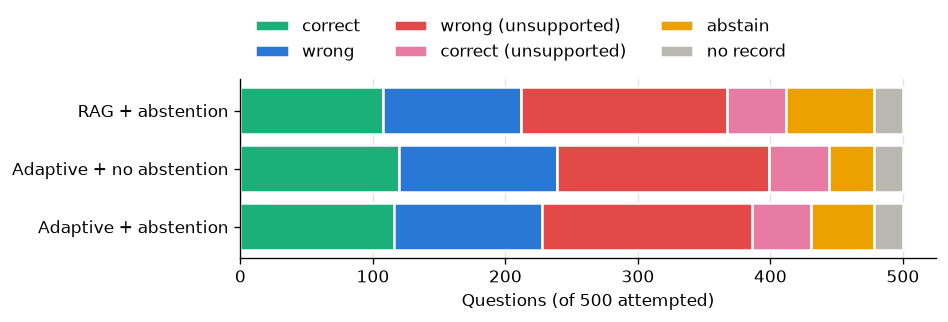

In [14]:
# Horizontal stacked bars - one bar per system, segments in a fixed outcome order.

fig, ax = plt.subplots(figsize=(8, 2.8))
left = pd.Series(0, index=counts.index)

for name, colour in OUTCOME_COLOURS.items():
    ax.barh(
        [SHORT[s] for s in counts.index], counts[name], left=left,
        color=colour, edgecolor="white", linewidth=1.5, label=name,
    )
    left += counts[name]
    
ax.invert_yaxis()
ax.set_xlabel("Questions (of 500 attempted)")
ax.legend(ncol=3, frameon=False, bbox_to_anchor=(0, 1.02), loc="lower left")
fig.tight_layout()
fig.savefig(FIGURES / "outcomes.png", bbox_inches="tight")

## What adaptive retrieval changed
Rows: outcome under rag_abstention. Columns: outcome for the same question under the adaptive system.
Only questions whose outcome changed are counted.

In [15]:
wide = df.pivot(index="question_id", columns="system", values="outcome")


def transitions(target: str) -> pd.DataFrame:
    """Count how each question's outcome moved from rag_abstention to the target system."""
    changed = wide[wide["rag_abstention"] != wide[target]]
    return pd.crosstab(changed["rag_abstention"], changed[target])


print("Adaptive + abstention")
display(transitions("adaptive_retrieval_abstention"))
print("Adaptive (always answers)")
display(transitions("adaptive_retrieval"))

Adaptive + abstention


adaptive_retrieval_abstention,correct,wrong,wrong (unsupported)
rag_abstention,,,
abstain,8,8,3


Adaptive (always answers)


adaptive_retrieval,correct,wrong,wrong (unsupported)
rag_abstention,,,
abstain,12,15,5


In [16]:
# Questions that got WORSE: a correct answer under the baseline, anything else under adaptive.
for target in ["adaptive_retrieval", "adaptive_retrieval_abstention"]:
    worse = wide[(wide["rag_abstention"] == "correct") & (wide[target] != "correct")]
    print(f"{SHORT[target]}: {len(worse)} questions got worse")

Adaptive + no abstention: 0 questions got worse
Adaptive + abstention: 0 questions got worse


## By round-0 evidence condition
complete = both gold paragraphs in the top 3; partially / fully incomplete = one / none.

In [17]:
def summarise(group: pd.DataFrame) -> pd.Series:
    answered = group[group.answered]
    em = answered["em"].astype(float)
    return pd.Series({
        "questions": len(group),
        "answered": len(answered),
        "abstained": int((~group.answered).sum()),
        "EM (answered)": round(em.mean(), 3) if len(answered) else None,
        "EM correct": int(em.sum()),
    })


by_condition = (
    df.groupby(["condition", "system"]).apply(summarise, include_groups=False)
    .unstack("system")
)
by_condition

questions                                \
system               adaptive_retrieval adaptive_retrieval_abstention   
condition                                                               
complete                          228.0                         228.0   
fully_incomplete                   19.0                          19.0   
partially_incomplete              231.0                         231.0   

                                              answered  \
system               rag_abstention adaptive_retrieval   
condition                                                
complete                      228.0              218.0   
fully_incomplete               19.0               16.0   
partially_incomplete          231.0              210.0   

                                                                   \
system               adaptive_retrieval_abstention rag_abstention   
condition                                                           
complete                                     214.0          212.0   
fully_incomplete                              15.0           13.0   
partially_incomplete                         202.0          187.0   

                              abstained                                \
system               adaptive_retrieval adaptive_retrieval_abstention   
condition                                                               
complete                           10.0                          14.0   
fully_incomplete                    3.0                           4.0   
partially_incomplete               21.0                          29.0   

                                         EM (answered)  \
system               rag_abstention adaptive_retrieval   
condition                                                
complete                       16.0              0.505   
fully_incomplete                6.0              0.000   
partially_incomplete           44.0              0.262   

                                                                   \
system               adaptive_retrieval_abstention rag_abstention   
condition                                                           
complete                                     0.505          0.509   
fully_incomplete                             0.000          0.000   
partially_incomplete                         0.262          0.241   

                             EM correct                                \
system               adaptive_retrieval adaptive_retrieval_abstention   
condition                                                               
complete                          110.0                         108.0   
fully_incomplete                    0.0                           0.0   
partially_incomplete               55.0                          53.0   

                                     
system               rag_abstention  
condition                            
complete                      108.0  
fully_incomplete                0.0  
partially_incomplete           45.0

## Where recovery is lost
Starts from questions whose round-0 evidence was incomplete. Each bar is a subset of the one above.

Round-0 evidence incomplete    250
Model asked for more            39
Follow-up assessed              33
Evidence now complete           24
Answered after recovery         14
Exact match                      8
dtype: int64

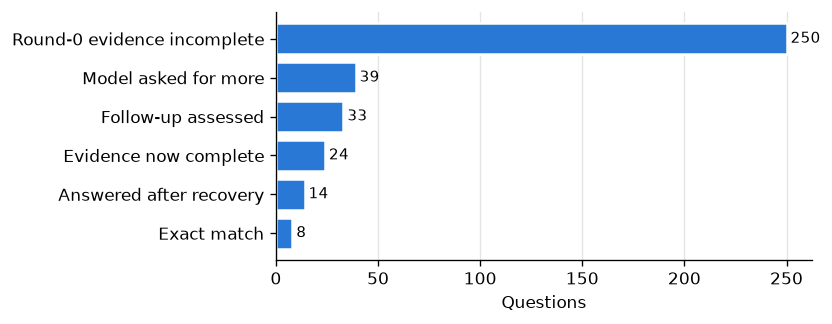

In [18]:
adaptive = df[df.system == "adaptive_retrieval_abstention"]
start = adaptive[~adaptive.gold_init]

funnel = pd.Series({
    "Round-0 evidence incomplete": len(start),
    "Model asked for more": int((start.round0_status == "need_more_evidence").sum()),
    "Follow-up assessed": int((start.rounds > 1).sum()),
    "Evidence now complete": int(start.gold_final.sum()),
    "Answered after recovery": int((start.gold_final & start.answered).sum()),
    "Exact match": int((start.gold_final & start.answered & (start.em == True)).sum()),
})

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(funnel.index, funnel.values, color="#2a78d6", edgecolor="white", linewidth=1.5)
for y, value in enumerate(funnel.values):
    ax.text(value + 2, y, str(value), va="center", fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("Questions")
fig.tight_layout()
fig.savefig(FIGURES / "recovery_funnel.png", bbox_inches="tight")
funnel

## Failure analysis

In [19]:
# Invalid model output, grouped by cause

def failure_cause(message: str) -> str:
    if "absent from supplied evidence" in message:
        ids = message.split(":", 1)[1].split(",")
        if any("::" not in i.strip() for i in ids):
            return "cited ID without ::0"
        return "cited ID not in evidence"
    if "question_id mismatch" in message:
        return "wrong question_id"
    if "missing keys" in message:
        return "missing JSON keys"
    return "other"


errors = []
for system, run_id in RUNS.items():
    with open(OUTPUTS / run_id / "errors.jsonl", encoding="utf-8") as f:
        for line in f:
            e = json.loads(line)
            errors.append({"system": system, "task": e["task"], "cause": failure_cause(e["message"])})

pd.crosstab(pd.DataFrame(errors)["cause"], pd.DataFrame(errors)["system"])

system,adaptive_retrieval,adaptive_retrieval_abstention,rag_abstention
cause,,,
cited ID not in evidence,1,1,1
cited ID without ::0,28,28,34
missing JSON keys,0,0,2
other,0,0,1
wrong question_id,2,2,2


In [20]:
# Three behaviours 

base = df[df.system == "rag_abstention"]
answered = base[base.answered]

false_sufficiency = base[~base.gold_final & (base.round0_status == "sufficient")]
lucky = answered[~answered.gold_final & (answered.em == True)]

verbose = answered[
    (answered.em == False)
    & answered.apply(
        lambda r: f" {normalize_answer(r.gold)} " in f" {normalize_answer(r.answer)} ", axis=1
    )
]
forced = df[df.system == "adaptive_retrieval"]

print("Judged sufficient on incomplete evidence:", len(false_sufficiency))
print("Correct answer despite incomplete evidence (guess or prior knowledge):", len(lucky))
print("EM miss but answer contains the gold answer (verbosity):", len(verbose))
print("adaptive_retrieval refusals (insufficient_evidence):",
      int((forced.abstention_reason == "insufficient_evidence").sum()))

Judged sufficient on incomplete evidence: 211
Correct answer despite incomplete evidence (guess or prior knowledge): 45
EM miss but answer contains the gold answer (verbosity): 57
adaptive_retrieval refusals (insufficient_evidence): 0


## Example cases to use in report
One clean recovery, one recovery the model didn't use, and one false sufficiency

In [21]:
def show(system: str, question_id: str) -> None:
    """Print one record: question, rounds, decision and final answer."""
    with open(OUTPUTS / RUNS[system] / "results.jsonl", encoding="utf-8") as f:
        record = next(r for r in map(json.loads, f) if r["question"]["question_id"] == question_id)
    print("Q:", record["question"]["question"])
    print("Gold:", record["question"]["gold_answer"], "| support:", record["question"]["gold_support_ids"])
    for rnd in record["rounds"]:
        ids = [c["evidence_id"] for c in rnd["retrieval"]["evidence"]]
        decision = rnd["sufficiency_decision"]
        print(f"  round {rnd['round_index']}: {ids} -> {decision['status']}", decision.get("search_query") or "")
    print("Final:", record["final_answer"]["answer"], "| abstained:", record["final_answer"]["abstained"])
    print()


# One clean recovery, one recovery the model failed to use, one false sufficiency.
recovered = adaptive[~adaptive.gold_init & adaptive.gold_final & (adaptive.em == True)]
unused = adaptive[~adaptive.gold_init & adaptive.gold_final & ~adaptive.answered]
for qid in [recovered.question_id.iloc[0], unused.question_id.iloc[0], false_sufficiency.question_id.iloc[0]]:
    show("adaptive_retrieval_abstention", qid)

Q: The release of One Night in Vegas was one of the largest turnouts ever in the history of Silverbird theater in a mall that was commissioned on July 4, 2008, and is owned by who?
Gold: Atterbury Property Development, Sanlam and the Morladza family | support: ['accra-mall::0', 'one-night-in-vegas::0']
  round 0: ['one-night-in-vegas::0', 'one-night-stand-2008::0', 'wwe-one-night-stand::0'] -> need_more_evidence Who owns Accra Mall?
  round 1: ['accra-mall::0', 'the-shoppes-at-gateway::0', 'one-night-elo-part-ii-album::0'] -> sufficient 
Final: Atterbury Property Development, Sanlam and the Morladza family | abstained: False

Q: Which actor, born in 1936, starred in the 2008 film Lords of the Street, also known as Jump Out Boys, and was also in the music supergroup, The Highwaymen.
Gold: Kris Kristofferson | support: ['kris-kristofferson::0', 'lords-of-the-street::0']
  round 0: ['lords-of-the-street::0', 'jonah-hill::0', 'sebastian-ingrosso::0'] -> need_more_evidence actor born in 193